# Q4-Q6: controlled Intel Arc XPU experiments
FP32; hidden dimension 16; node embeddings 8; Adam 0.002; batch 64; maximum 20 epochs; early stopping patience 5; seed 25280025. Every epoch uses all training windows. Checkpoint selection uses the complete validation period. Each model is evaluated on the complete common test period only after selection.

In [1]:
from pathlib import Path
import sys, subprocess, json
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').is_dir()
def run(script,*args):
    command=[sys.executable,str(ROOT/'src'/script),*args]
    log=ROOT/'results'/(script.replace('.py','')+('_'+args[-1] if args else '')+'.log')
    with log.open('w',encoding='utf-8') as f:
        result=subprocess.run(command,cwd=ROOT,stdout=f,stderr=subprocess.STDOUT)
    print(log.read_text(encoding='utf-8')[-16000:])
    result.check_returncode()
def show(name):
    display(Image(filename=str(ROOT/'figures'/name)))

In [2]:
import torch
print(torch.__version__,torch.xpu.is_available(),torch.xpu.get_device_name())
assert torch.xpu.is_available()

2.14.1+xpu True Intel(R) Arc(TM) 140T GPU (23GB)


## Model implementation
The temporal encoder and forecast head are shared designs. The temporal baseline retains the same channel projection, using identity node mixing. Fixed adjacency is row normalized because the supplied road graph may be directed. Adaptive adjacency uses dense row softmax of ReLU of two learned embedding products; hybrid mixing uses alpha=0.5. No test-dependent graph construction occurs.

In [3]:
print((ROOT/'src'/'models.py').read_text())

"""The same lightweight temporal encoder, projection, and head for all four models."""
import torch
from torch import nn

class Forecaster(nn.Module):
    def __init__(self, mode, fixed, hidden=16, embedding=8, alpha=.5):
        super().__init__()
        self.mode=mode
        self.alpha=alpha
        self.temporal=nn.Sequential(nn.Conv2d(1,hidden,(1,3),padding=(0,1)),nn.ReLU(),
                                    nn.Conv2d(hidden,hidden,(1,3),padding=(0,1)),nn.ReLU())
        self.pool=nn.Linear(hidden*8,hidden)
        self.spatial=nn.Linear(hidden,hidden,bias=False)
        self.head=nn.Linear(hidden,4)
        self.register_buffer('fixed',fixed.clone())
        if mode in ['adaptive','hybrid']:
            self.E1=nn.Parameter(torch.randn(len(fixed),embedding)*.1)
            self.E2=nn.Parameter(torch.randn(len(fixed),embedding)*.1)
        self.register_buffer('frozen_graph',None)

    def adjacency(self):
        if self.frozen_graph is not None:
            return self.frozen

## Temporal

In [4]:
run('train.py','--modes','temporal')

temporal {'epoch': 1, 'train_mae': 78.6024169921875, 'val_mae': 61.50243334744995, 'val_rmse': 98.85659196086048, 'seconds': 14.740334700007224}
temporal {'epoch': 2, 'train_mae': 59.54846954345703, 'val_mae': 61.64767071808879, 'val_rmse': 98.7641743668157, 'seconds': 12.830278199995519}
temporal {'epoch': 3, 'train_mae': 58.79142761230469, 'val_mae': 60.482821034654926, 'val_rmse': 96.89647980900847, 'seconds': 12.834977600010461}
temporal {'epoch': 4, 'train_mae': 58.58696746826172, 'val_mae': 60.05768187451172, 'val_rmse': 96.58428761770826, 'seconds': 12.872405899994192}
temporal {'epoch': 5, 'train_mae': 58.16206359863281, 'val_mae': 59.455961037852816, 'val_rmse': 95.62889196163219, 'seconds': 12.79377229999227}
temporal {'epoch': 6, 'train_mae': 57.91920852661133, 'val_mae': 58.92830468689544, 'val_rmse': 95.31672162087436, 'seconds': 12.905038400000194}
temporal {'epoch': 7, 'train_mae': 57.74516296386719, 'val_mae': 58.95204088904622, 'val_rmse': 94.98628232245993, 'seconds':

## Fixed

In [5]:
run('train.py','--modes','fixed')

fixed {'epoch': 1, 'train_mae': 139.53640747070312, 'val_mae': 127.51424884782024, 'val_rmse': 193.3978771991768, 'seconds': 20.55891690000135}
fixed {'epoch': 2, 'train_mae': 123.08391571044922, 'val_mae': 125.03684094895388, 'val_rmse': 190.01007131884666, 'seconds': 18.654631299999892}
fixed {'epoch': 3, 'train_mae': 120.39576721191406, 'val_mae': 123.28012294513366, 'val_rmse': 188.14750208235483, 'seconds': 18.60658429999603}
fixed {'epoch': 4, 'train_mae': 117.39230346679688, 'val_mae': 120.75259579753623, 'val_rmse': 183.11884051283334, 'seconds': 18.725108700004057}
fixed {'epoch': 5, 'train_mae': 115.04418182373047, 'val_mae': 118.12657295308745, 'val_rmse': 182.45515104885342, 'seconds': 18.631931700001587}
fixed {'epoch': 6, 'train_mae': 113.28581237792969, 'val_mae': 116.25913511030093, 'val_rmse': 180.14563380348142, 'seconds': 18.74908090000099}
fixed {'epoch': 7, 'train_mae': 112.0288314819336, 'val_mae': 115.11539612863119, 'val_rmse': 179.302325046138, 'seconds': 18.49

## Adaptive

In [6]:
run('train.py','--modes','adaptive')

adaptive {'epoch': 1, 'train_mae': 151.61204528808594, 'val_mae': 110.55936625502842, 'val_rmse': 174.96056908123944, 'seconds': 22.968874300000607}
adaptive {'epoch': 2, 'train_mae': 106.31413269042969, 'val_mae': 110.01564681530293, 'val_rmse': 175.10678850217326, 'seconds': 22.3521294999955}
adaptive {'epoch': 3, 'train_mae': 105.399169921875, 'val_mae': 109.19170640834447, 'val_rmse': 174.96433137655174, 'seconds': 21.00700080000388}
adaptive {'epoch': 4, 'train_mae': 105.14583587646484, 'val_mae': 108.02550909877749, 'val_rmse': 172.87834666560212, 'seconds': 20.928574699995806}
adaptive {'epoch': 5, 'train_mae': 104.8482666015625, 'val_mae': 108.51842270421041, 'val_rmse': 171.42985686966136, 'seconds': 20.886359800002538}
adaptive {'epoch': 6, 'train_mae': 104.40076446533203, 'val_mae': 111.03889447961942, 'val_rmse': 172.4904983891346, 'seconds': 20.87506730000314}
adaptive {'epoch': 7, 'train_mae': 104.38154602050781, 'val_mae': 108.3766576614159, 'val_rmse': 171.9022765638039

## Hybrid

In [7]:
run('train.py','--modes','hybrid')

hybrid {'epoch': 1, 'train_mae': 133.5783233642578, 'val_mae': 98.30504912479837, 'val_rmse': 152.5049073348808, 'seconds': 23.474769899999956}
hybrid {'epoch': 2, 'train_mae': 91.01567077636719, 'val_mae': 93.77305545482858, 'val_rmse': 150.07730453544727, 'seconds': 21.16987200001313}
hybrid {'epoch': 3, 'train_mae': 89.30821990966797, 'val_mae': 93.01026961376967, 'val_rmse': 148.56691865687458, 'seconds': 21.27487559999281}
hybrid {'epoch': 4, 'train_mae': 88.8358154296875, 'val_mae': 91.90731070144528, 'val_rmse': 147.2123667749817, 'seconds': 21.455216499991366}
hybrid {'epoch': 5, 'train_mae': 88.27255249023438, 'val_mae': 93.53919120113135, 'val_rmse': 148.0299899817807, 'seconds': 21.20304049999686}
hybrid {'epoch': 6, 'train_mae': 87.47171783447266, 'val_mae': 91.48807876232945, 'val_rmse': 146.05883991886694, 'seconds': 21.157257899991237}
hybrid {'epoch': 7, 'train_mae': 86.97174835205078, 'val_mae': 91.31345927011581, 'val_rmse': 145.70526476848664, 'seconds': 21.261580499

## Saved-checkpoint analysis
Predictions use graph-order sensors 0,358,715 and predetermined April dates. Top-10 graph analysis excludes self-links and compares with the physical graph and a uniform-pair geographic reference.

In [8]:
run('analyze.py')
print((ROOT/'results'/'metrics.json').read_text())

{
  "reference": {
    "road_nonself_density": 0.033830136344102826,
    "all_pairs_mean_distance_km": 27.09164706813094,
    "all_pairs_under_5km_fraction": 0.058995194749384694,
    "road_edges_mean_distance_km": 2.2795987002687443
  },
  "adaptive": {
    "top10_road_overlap": 0.04399441340782123,
    "top10_mean_distance_km": 24.59739602393445,
    "top10_median_distance_km": 21.60518245754068,
    "top10_under_5km_fraction": 0.06522346368715083,
    "top10_edges": 7160,
    "mean_row_entropy": 6.313493728637695,
    "uniform_entropy": 6.573680166960646,
    "mean_self_weight": 0.0018671287689357996
  },
  "hybrid": {
    "top10_road_overlap": 0.053631284916201116,
    "top10_mean_distance_km": 22.223077779636043,
    "top10_median_distance_km": 19.15365294937045,
    "top10_under_5km_fraction": 0.09567039106145252,
    "top10_edges": 7160,
    "mean_row_entropy": 4.208889007568359,
    "uniform_entropy": 6.573680166960646,
    "mean_self_weight": 0.0007682738360017538
  }
}

{
  "

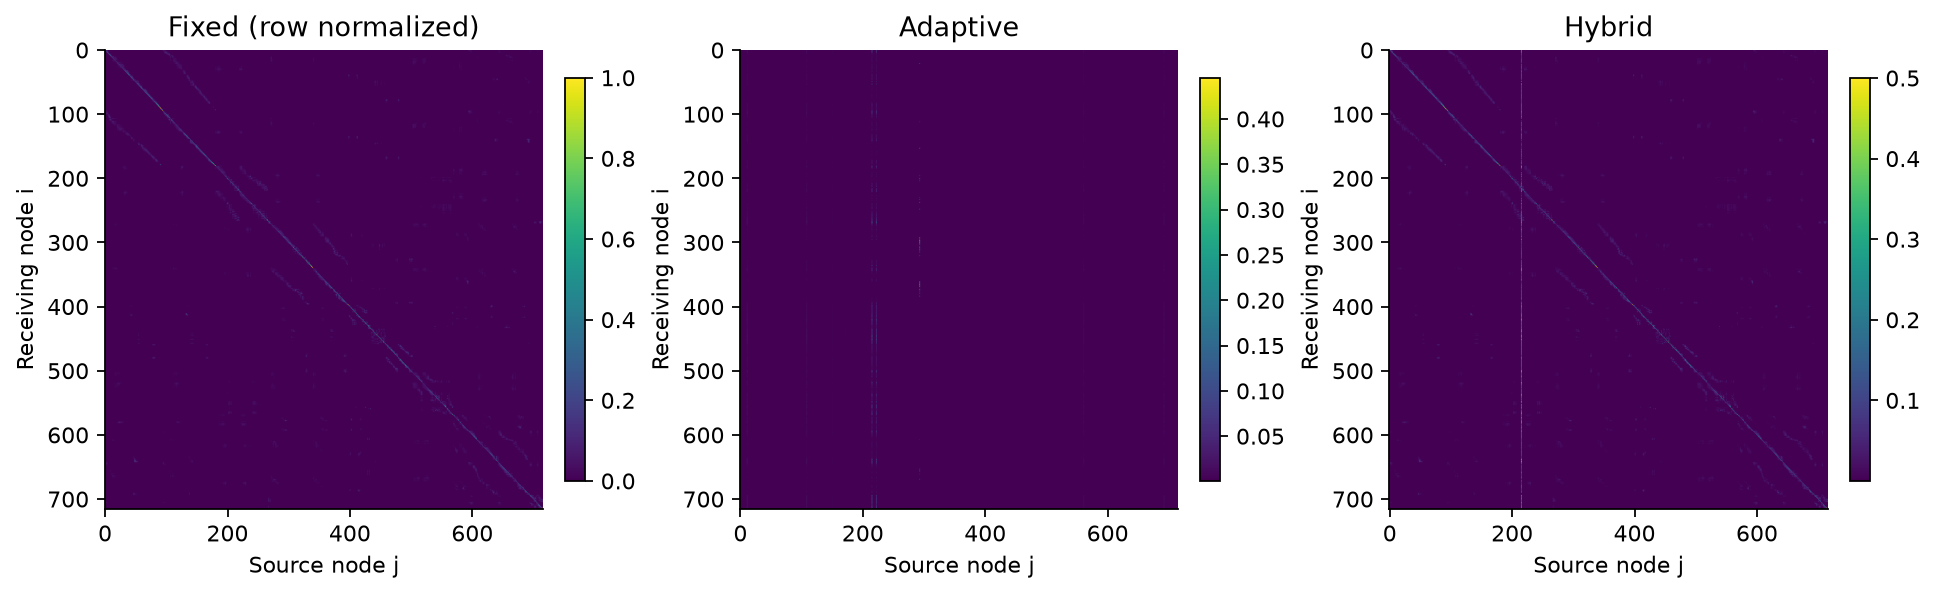

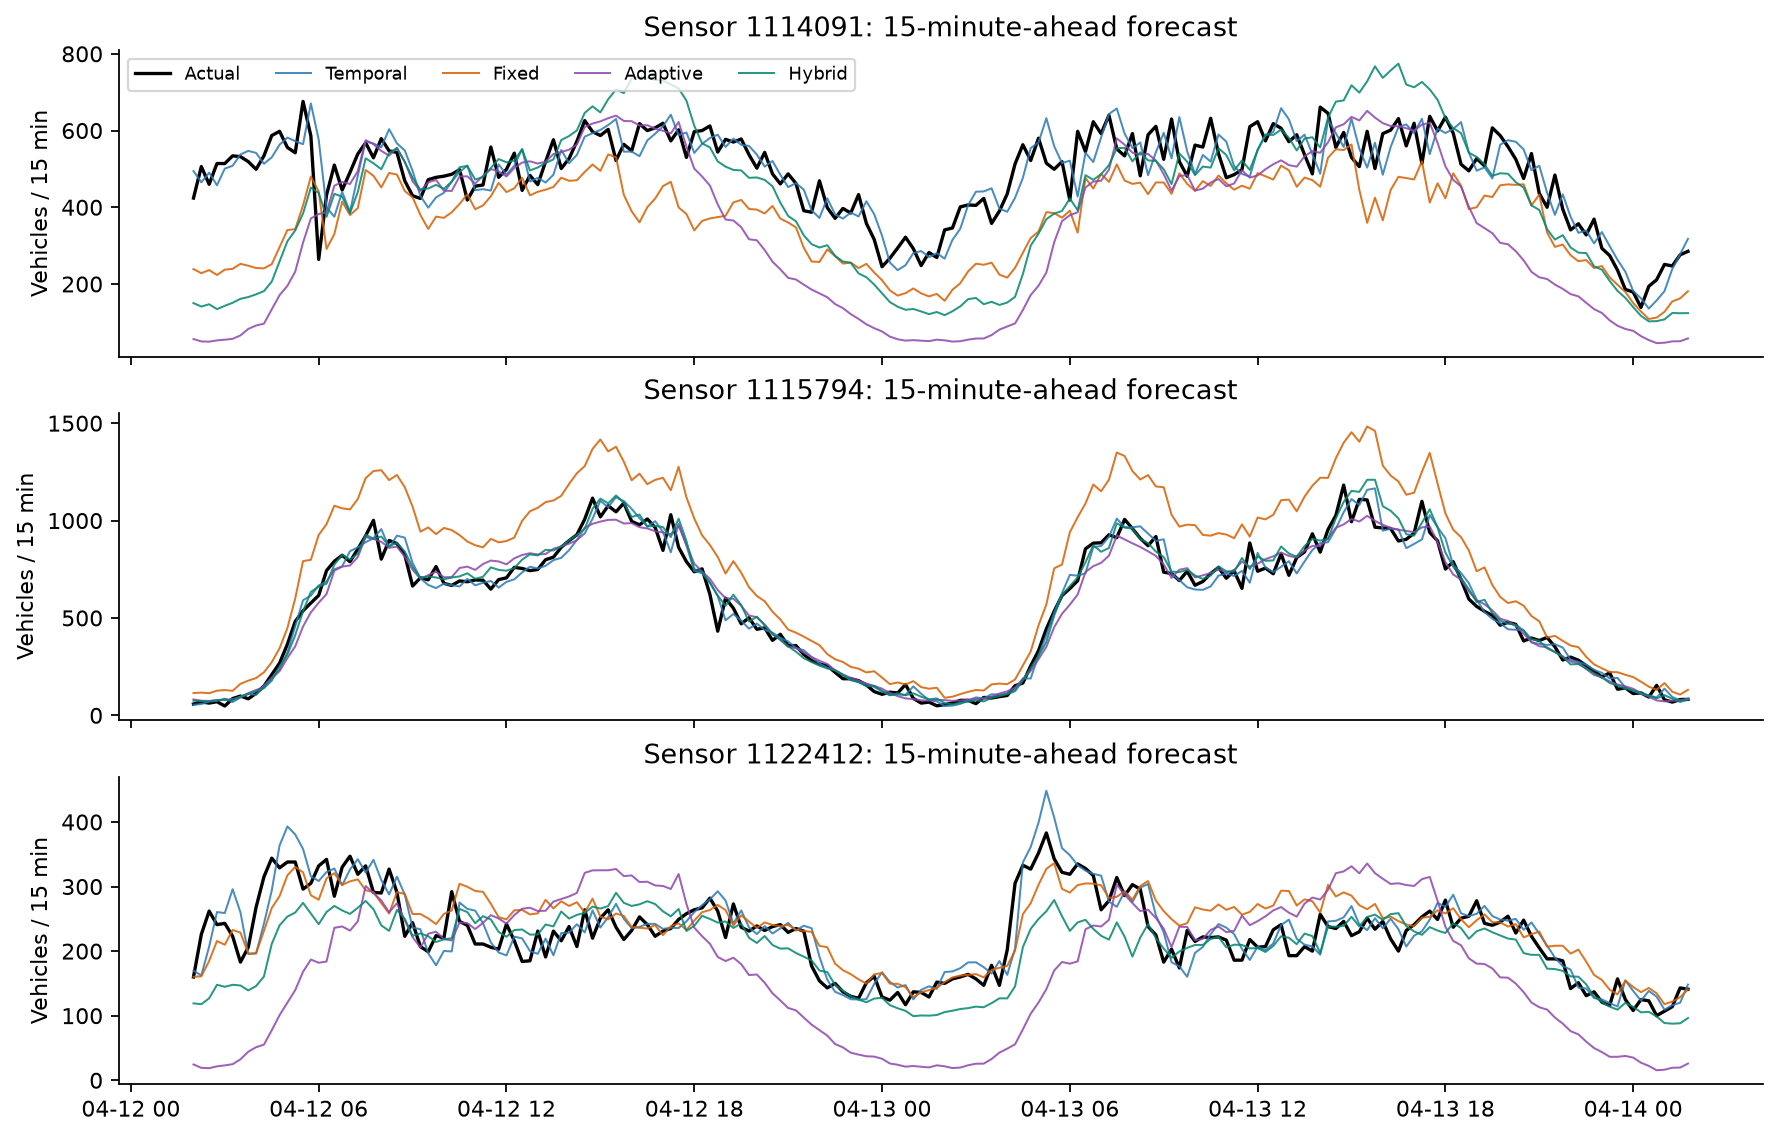

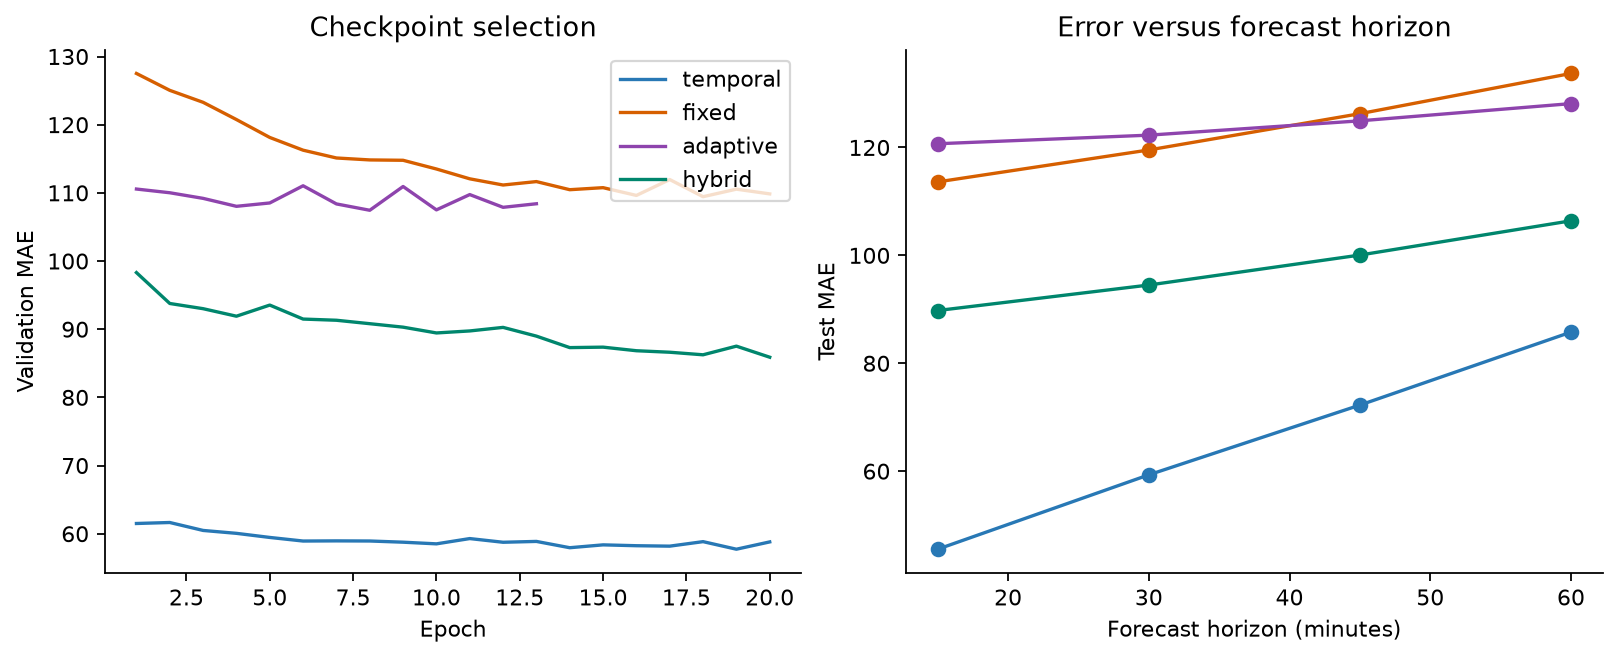

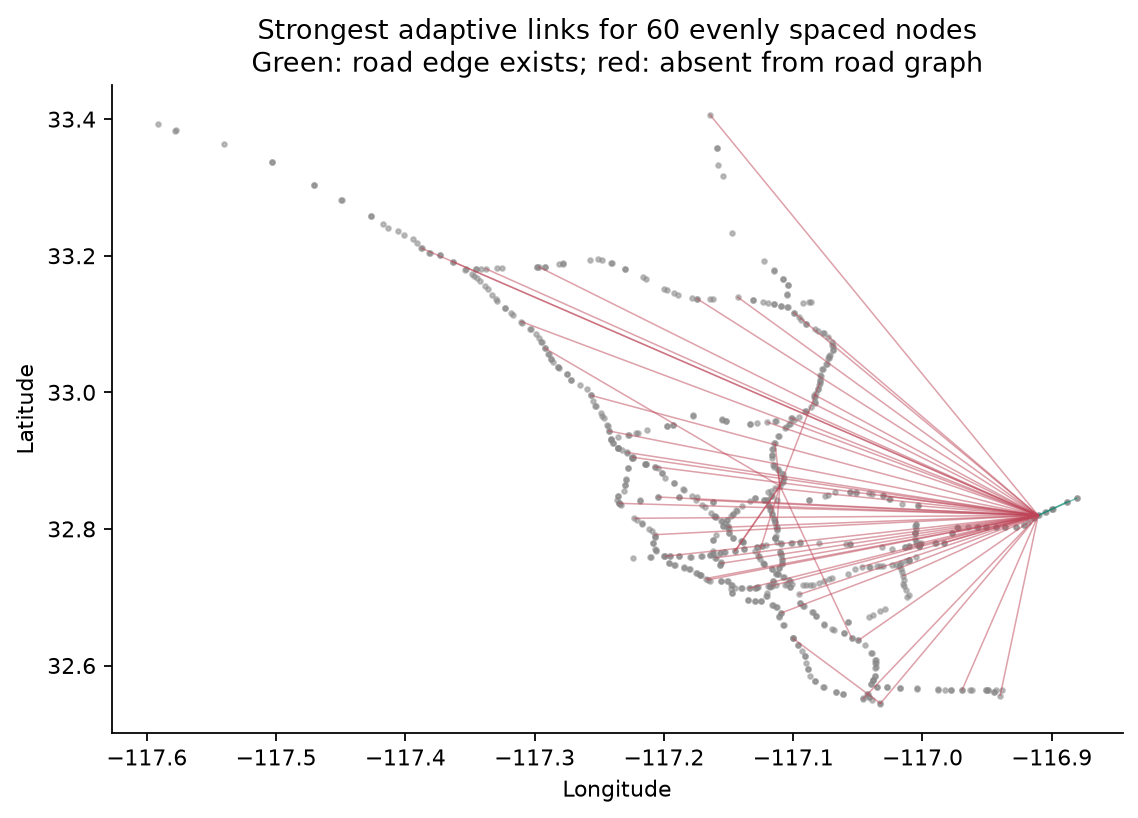

In [9]:
show('q5_adjacencies.png')
show('q6_predictions.png')
show('q6_learning.png')
show('q6_learned_map.png')